# Catching Fraudsters: fine-tuning BERT to detect fake job postings
Arnar Logi Jónsson, Zepei Zhao (group 089)

Binary classification of real vs. fraudulent job postings with `bert-base-cased`, using the EMSCAD dataset from Kaggle (17,880 postings, 4.8% fraudulent). We compare three setups: an MLP head on frozen BERT, fine-tuning the top 4 BERT layers with the head, and fine-tuning all of BERT. The settings cell below chooses the input text version and how many layers to train.

# Imports and settings

In [2]:
import os
import time

import numpy as np
import pandas as pd

from datasets import Dataset
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, DataCollatorWithPadding, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score
from sklearn.metrics import precision_recall_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
# Settings for running the notebook
RELOAD_MODEL = False            # download the tokenizer again instead of using the saved one
skip_unnecessary_stuff = False  # plots and token counts
skip_training = True            # skip the BERT fine-tuning (slow) and load the saved weights instead
text_ver = "text_full"          # "text" (sparse columns dropped) or "text_full" (extra columns, empty -> "None")
num_unfrozen = 4                # number of top BERT layers to fine-tune, None = all of BERT

In [ ]:
path = "google-bert/bert-base-cased"
if os.path.exists("tokenizer") and not RELOAD_MODEL:
    tokenizer = AutoTokenizer.from_pretrained("tokenizer")
else:
    tokenizer = AutoTokenizer.from_pretrained(path)
    tokenizer.save_pretrained("tokenizer")

# Preprocessing the dataset

In [71]:
# Load the dataset
path = "dataset/fake_job_postings.csv"
dataset = pd.read_csv(path)

print(dataset.columns)
print(dataset.fraudulent.value_counts())

columns = dataset.columns
for col in columns:
    print(f"{col}: {dataset[col].isnull().sum()}")

print("Original shape:", dataset.shape)

# Drop columns with too many missing values (more than 1000 missing values)
no_empty = dataset.dropna(axis="columns",thresh=dataset.shape[0]-1000)
print("Shape after dropping columns with too many missing values:", no_empty.shape)
# for text_full we keep all the columns and fill the empty ones with "None" instead
yes_empty = dataset.fillna("None")

# Drop rows with missing values in the 'description' column
no_empty = no_empty.dropna(subset=['description'])
print('Dropped no of rows:', dataset.shape[0]-no_empty.shape[0])
columns = no_empty.columns
for col in columns:
    print(f"{col}: {no_empty[col].isnull().sum()}")

print(no_empty.head())

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent'],
      dtype='str')
fraudulent
0    17014
1      866
Name: count, dtype: int64
job_id: 0
title: 0
location: 346
department: 11547
salary_range: 15012
company_profile: 3308
description: 1
requirements: 2696
benefits: 7212
telecommuting: 0
has_company_logo: 0
has_questions: 0
employment_type: 3471
required_experience: 7050
required_education: 8105
industry: 4903
function: 6455
fraudulent: 0
Original shape: (17880, 18)
Shape after dropping columns with too many missing values: (17880, 8)
Dropped no of rows: 1
job_id: 0
title: 0
location: 346
description: 0
telecommuting: 0
has_company_logo: 0
has_questions: 0
fraudulent: 0
   job_id                                      title      

## Visualization of the data

Not Fraudulent: 17014, Fraudulent: 865
Originally Not Fraudulent: 17014, Originally Fraudulent: 866


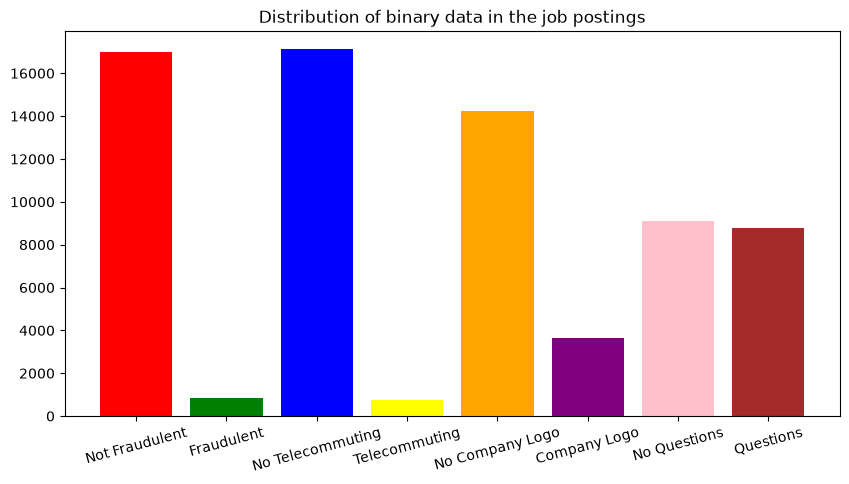

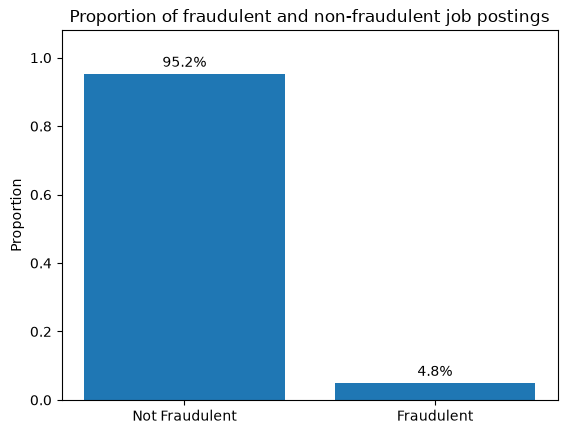

In [ ]:
if not skip_unnecessary_stuff:
    org1, org2 = dataset.fraudulent.value_counts()
    x1,x2 = no_empty.fraudulent.value_counts()
    x3,x4 = no_empty.telecommuting.value_counts()
    x5,x6 = no_empty.has_company_logo.value_counts()
    x7,x8 = no_empty.has_questions.value_counts()
    print(f"Not Fraudulent: {x1}, Fraudulent: {x2}")
    print(f"Originally Not Fraudulent: {org1}, Originally Fraudulent: {org2}")
    #plotting the distribution of fraudulent and non-fraudulent job postings

    plt.figure(figsize=(10,5))
    plt.bar(["Not Fraudulent", "Fraudulent", "No Telecommuting", "Telecommuting", "No Company Logo", "Company Logo", "No Questions", "Questions"], [x1, x2, x3, x4, x5, x6, x7, x8], color=["red", "green", "blue", "yellow", "orange", "purple", "pink", "brown"])
    plt.title("Distribution of binary data in the job postings")
    plt.xticks(rotation=15)
    # share of fraudulent postings
    x1,x2 = no_empty.fraudulent.value_counts(normalize=True)
    plt.figure()
    bars = plt.bar(["Not Fraudulent", "Fraudulent"], [x1, x2])
    plt.bar_label(bars, labels=[f"{x1:.1%}", f"{x2:.1%}"], padding=3)
    plt.ylim(0, 1.08)
    plt.ylabel("Proportion")
    plt.title("Proportion of fraudulent and non-fraudulent job postings")

In [7]:
# build the input strings for BERT
# two text versions per row:
#   text      -> same as before (binary cols + title, location, description)
#   text_full -> adds employment_type, requirements, benefits; empty values become "None"
binary_columns = ['telecommuting', 'has_company_logo', 'has_questions']
text_columns = ['title', 'location']
extra_columns = ['employment_type', 'requirements', 'benefits']
desc_column = ['description']

def is_empty(val):
    return val is None or pd.isna(val) or str(val).strip() == ""

def build_data_for_llm(row):
    """One string per posting, e.g. "telecommuting: no [SEP] ... [SEP] description: ..." """
    output = []
    for col in binary_columns:
        val = row[col]
        if is_empty(val):
            val = "N/A"
        output.append(f"{col}: {'yes' if val == 1 else 'no'}")
    for col in text_columns + desc_column:
        val = row[col]
        if is_empty(val):
            val = "N/A"
        output.append(f"{col}: {val}")
    return " [SEP] ".join(output)

def build_full_data_for_llm(row):
    """Same as above plus employment_type, requirements and benefits, empty fields become None"""
    output = []
    for col in binary_columns:
        val = row[col]
        if is_empty(val):
            output.append(f"{col}: None")
        else:
            output.append(f"{col}: {'yes' if val == 1 else 'no'}")
    for col in text_columns + extra_columns + desc_column:
        val = row[col]
        output.append(f"{col}: {'None' if is_empty(val) else str(val).strip()}")
    return " [SEP] ".join(output)

no_empty['text'] = no_empty.apply(build_data_for_llm, axis=1)
yes_empty['text_full'] = yes_empty.apply(build_full_data_for_llm, axis=1)

# align on index: keep the rows of no_empty, attach text_full from yes_empty
df = no_empty[["text", "fraudulent"]].join(yes_empty["text_full"], how="left")
df = df.rename(columns={"fraudulent": "labels"})[["text", "text_full", "labels"]]

print(df.shape, df.text_full.isna().sum())   # second number should be 0
print(df.head())

# separate into train, validation and test sets
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df["labels"], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, stratify=temp_df["labels"], random_state=42)

# the builder that matches text_ver, used later when classifying new postings
build_text = build_full_data_for_llm if text_ver == "text_full" else build_data_for_llm

# class weights from the training split, used for both the head and the fine-tuning
# (about 0.53 for real and 10.3 for fraudulent)
counts = np.bincount(train_df["labels"])
class_weights = torch.tensor(len(train_df) / (2 * counts), dtype=torch.float)

(17879, 3) 0
                                                text  \
0  telecommuting: no [SEP] has_company_logo: yes ...   
1  telecommuting: no [SEP] has_company_logo: yes ...   
2  telecommuting: no [SEP] has_company_logo: yes ...   
3  telecommuting: no [SEP] has_company_logo: yes ...   
4  telecommuting: no [SEP] has_company_logo: yes ...   

                                           text_full  labels  
0  telecommuting: no [SEP] has_company_logo: yes ...       0  
1  telecommuting: no [SEP] has_company_logo: yes ...       0  
2  telecommuting: no [SEP] has_company_logo: yes ...       0  
3  telecommuting: no [SEP] has_company_logo: yes ...       0  
4  telecommuting: no [SEP] has_company_logo: yes ...       0  


## Tokenization

In [8]:
# Tokenize the text data
train_ds = Dataset.from_pandas(train_df,preserve_index=False)
train_ds = train_ds.map(lambda b: tokenizer(b[text_ver], truncation=True, max_length=512), batched=True)
val_ds = Dataset.from_pandas(val_df,preserve_index=False)
val_ds = val_ds.map(lambda b: tokenizer(b[text_ver], truncation=True, max_length=512), batched=True)
test_ds = Dataset.from_pandas(test_df,preserve_index=False)
test_ds = test_ds.map(lambda b: tokenizer(b[text_ver], truncation=True, max_length=512), batched=True)

Map: 100%|██████████| 1788/1788 [00:00<00:00, 3872.34 examples/s]


In [ ]:
# how many postings are longer than BERT's 512 token limit (the end of those gets cut off)
if not skip_unnecessary_stuff:
    for name, ds in [("train", train_ds), ("val", val_ds), ("test", test_ds)]:
        truncated = sum(len(ids) >= 512 for ids in ds["input_ids"])
        print(f"{name}: {truncated} of {ds.num_rows} postings hit the 512 token limit")

In [10]:

def output_to_label(z, threshold=0.5):
    """Map network output z to a hard label {0, 1}

    Args:
        z (Tensor, (B, 2)): Logits for [real, fraudulent] for each sample in a batch.
        threshold (float): Fraud probability at or above which a sample is labelled 1.
    Returns:
        c (Tensor, (B,)): Hard label {0, 1} for each sample in a batch
    """
    probs = torch.softmax(z, dim=-1)[:, 1]
    c = (probs >= threshold).long()
    return c

def training_loop(
    model, optimizer, loss_fn, train_loader, val_loader, num_epochs, print_every,
    save_path=None, **train_kwargs
):
    """`save_path`: if given, the best weights are also written to disk whenever they improve.
    `train_kwargs` are passed on to train_epoch (scaler, scheduler, log_every)."""
    print("Starting training")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    model.to(device)
    train_losses, train_accs, val_losses, val_metrics = [], [], [], []
    # Keep the epoch with the best val PR-AUC (threshold-independent, so a fair way to pick)
    best_pr_auc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, num_epochs + 1):
        start = time.time()
        model, train_loss, train_acc = train_epoch(
            model, optimizer, loss_fn, train_loader, val_loader, device, print_every, **train_kwargs
        )
        val_loss, metrics = validate(model, loss_fn, val_loader, device)
        print(
            f"Epoch {epoch}/{num_epochs}: "
            f"Train loss: {sum(train_loss)/len(train_loss):.3f}, "
            f"Val. loss: {val_loss:.3f}, "
            f"Val. F1: {metrics['f1']:.3f}, "
            f"Val. precision: {metrics['precision']:.3f}, "
            f"Val. recall: {metrics['recall']:.3f}, "
            f"Val. PR-AUC: {metrics['pr_auc']:.3f} "
            f"({(time.time() - start) / 60:.1f} min)"
        )
        train_losses.extend(train_loss)
        train_accs.extend(train_acc)
        val_losses.append(val_loss)
        val_metrics.append(metrics)

        if metrics["pr_auc"] > best_pr_auc:
            best_pr_auc, best_epoch = metrics["pr_auc"], epoch
            # Copy to CPU so the backup doesn't take GPU memory
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            if save_path is not None:
                torch.save(best_state, save_path)
                print(f"\tSaved best weights to {save_path}")

    model.load_state_dict(best_state)
    print(f"Restored weights from epoch {best_epoch} (val PR-AUC {best_pr_auc:.3f})")
    return model, train_losses, train_accs, val_losses, val_metrics


def train_epoch(
    model, optimizer, loss_fn, train_loader, val_loader, device, print_every,
    scaler=None, scheduler=None, log_every=None
):
    """`scaler`: GradScaler for fp16 training. `scheduler`: stepped after every batch.
    `log_every`: print running train loss every N batches (cheap, no validation)."""
    # Train:
    model.train()
    train_loss_batches, train_acc_batches = [], []
    num_batches = len(train_loader)
    start = time.time()
    for batch_index, (x, y) in enumerate(train_loader, 1):
        inputs, labels = x.to(device), y.to(device)
        optimizer.zero_grad()
        z = model.forward(inputs)
        loss = loss_fn(z, labels)
        if scaler is not None:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        if scheduler is not None:
            scheduler.step()
        train_loss_batches.append(loss.item())

        hard_preds = output_to_label(z)
        acc_batch_avg = (hard_preds == labels).float().mean().item()
        train_acc_batches.append(acc_batch_avg)

        if log_every is not None and batch_index % log_every == 0:
            elapsed = time.time() - start
            print(
                f"\tBatch {batch_index}/{num_batches}: "
                f"Train loss: {sum(train_loss_batches[-log_every:])/log_every:.3f}, "
                f"elapsed {elapsed / 60:.1f} min, "
                f"epoch ETA {elapsed / batch_index * (num_batches - batch_index) / 60:.1f} min"
            )

        # If you want to print your progress more often than every epoch you can
        # set `print_every` to the number of batches you want between every status update.
        # Note that the print out will trigger a full validation on the full val. set => slows down training
        if print_every is not None and batch_index % print_every == 0:
            val_loss, metrics = validate(model, loss_fn, val_loader, device)
            model.train()
            print(
                f"\tBatch {batch_index}/{num_batches}: "
                f"\tTrain loss: {sum(train_loss_batches[-print_every:])/print_every:.3f}, "
                f"\tVal. loss: {val_loss:.3f}, "
                f"\tVal. F1: {metrics['f1']:.3f}, "
                f"\tVal. PR-AUC: {metrics['pr_auc']:.3f}"
            )

    return model, train_loss_batches, train_acc_batches


def predict_logits(model, loader, device):
    """Run the model over a whole loader and return (logits, labels) on the CPU."""
    model.eval()
    logits, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            logits.append(model.forward(x.to(device)).float().cpu())
            labels.append(y)
    return torch.cat(logits), torch.cat(labels)


def validate(model, loss_fn, val_loader, device, threshold=0.5):
    # Accuracy is misleading at ~5% fraud (always guessing "real" gives 95%),
    # so report precision/recall/F1 for the fraud class and PR-AUC instead.
    logits, labels = predict_logits(model, val_loader, device)
    val_loss = loss_fn(logits.to(device), labels.to(device)).item()
    probs = torch.softmax(logits, dim=-1)[:, 1].numpy()
    preds = output_to_label(logits, threshold).numpy()
    y = labels.numpy()
    metrics = {
        "acc": (preds == y).mean(),
        "precision": precision_score(y, preds, zero_division=0),
        "recall": recall_score(y, preds),
        "f1": f1_score(y, preds),
        "pr_auc": average_precision_score(y, probs),
    }
    return val_loss, metrics


def evaluate(model, val_loader, test_loader, device, title):
    """Pick the decision threshold on validation, then report on the test set once:
    classification report + confusion matrix (counts and normalized per true class)."""
    # 0.5 is rarely the best threshold under class weighting, so choose the one with the best val F1
    logits, labels = predict_logits(model, val_loader, device)
    val_probs = torch.softmax(logits, dim=-1)[:, 1].numpy()
    p, r, t = precision_recall_curve(labels.numpy(), val_probs)
    f1s = 2 * p * r / (p + r + 1e-9)
    best_t = t[np.argmax(f1s[:-1])]
    print(f"best threshold on val: {best_t:.3f}  (val F1 {f1s[:-1].max():.3f})")

    logits, labels = predict_logits(model, test_loader, device)
    y = labels.numpy()
    test_probs = torch.softmax(logits, dim=-1)[:, 1].numpy()
    test_preds = (test_probs >= best_t).astype(int)
    print("test PR-AUC:", average_precision_score(y, test_probs))
    print(classification_report(y, test_preds, digits=3))

    cm = confusion_matrix(y, test_preds)
    class_names = ["Not Fraudulent", "Fraudulent"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{title}: test counts (threshold = {best_t:.2f})")
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=class_names).plot(
        ax=axes[1], cmap="Blues", colorbar=False, values_format=".1%"
    )
    axes[1].set_title("Normalized per true class")
    plt.tight_layout()
    plt.show()

    tn, fp, fn, tp = cm.ravel()
    print(f"Caught {tp} of {tp + fn} fraudulent postings, missed {fn}; {fp} real postings flagged as fraud")
    return best_t, test_probs

In [ ]:
class MLPHead(torch.nn.Module):
    """Small MLP that classifies a 768-dim BERT embedding as real or fraudulent."""

    def __init__(self, in_dim=768, hidden_dim=256, dropout=0.3, num_classes=2):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(in_dim, hidden_dim),
            torch.nn.ReLU(),
            torch.nn.Dropout(dropout),
            torch.nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)

In [ ]:
# Mean-pooled embeddings from frozen BERT, one vector per posting.
# Computing them takes a while, so they are saved to a file (one per text version).
emb_path = f"embeddings_{text_ver}.npz"

def embed(ds, encoder, batch_size=64):
    collator = DataCollatorWithPadding(tokenizer)
    ds = ds.remove_columns([c for c in ds.column_names
                            if c not in ("input_ids", "attention_mask", "token_type_ids")])
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, collate_fn=collator)
    out = []
    with torch.no_grad(), torch.autocast(device_type=device.type, enabled=device.type == "cuda"):
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            hidden = encoder(**batch).last_hidden_state            # (B, T, 768)
            mask = batch["attention_mask"].unsqueeze(-1).float()   # (B, T, 1)
            mean = (hidden * mask).sum(1) / mask.sum(1)            # ignore padding
            out.append(mean.float().cpu().numpy())
    return np.concatenate(out)

if not os.path.exists(emb_path):
    encoder = AutoModel.from_pretrained("google-bert/bert-base-cased").to(device)
    encoder.eval()
    np.savez(emb_path,
             X_train=embed(train_ds, encoder), y_train=np.array(train_ds["labels"]),
             X_val=embed(val_ds, encoder), y_val=np.array(val_ds["labels"]),
             X_test=embed(test_ds, encoder), y_test=np.array(test_ds["labels"]))
    del encoder
    torch.cuda.empty_cache()

data = np.load(emb_path)
X_train, y_train = data["X_train"], data["y_train"]
X_val, y_val = data["X_val"], data["y_val"]
X_test, y_test = data["X_test"], data["y_test"]

# Baseline with a frozen Bert model and a Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

clf = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, class_weight="balanced", C=1.0),
)
clf.fit(X_train, y_train)

val_probs = clf.predict_proba(X_val)[:, 1]
print("val PR-AUC:", average_precision_score(y_val, val_probs))

# Choose the threshold on validation
p, r, t = precision_recall_curve(y_val, val_probs)
f1s = 2 * p * r / (p + r + 1e-9)
best_t = t[np.argmax(f1s[:-1])]
print("best threshold:", best_t, "val F1:", f1s[:-1].max())

# Test once, at the end
test_probs = clf.predict_proba(X_test)[:, 1]
print("test PR-AUC:", average_precision_score(y_test, test_probs))
print(classification_report(y_test, (test_probs >= best_t).astype(int), digits=3))

# Training the MLP head on frozen BERT embeddings
BERT is frozen here, so the embeddings from above can be reused and only `MLPHead` is trained. This only takes seconds, so the head is always trained when the notebook runs. The class imbalance (about 20:1) is handled with the class-weighted loss, and the decision threshold is tuned on the validation set afterwards.

In [14]:
# Standardize with TRAINING statistics only (same idea as the StandardScaler above)
mu, sigma = X_train.mean(axis=0), X_train.std(axis=0) + 1e-6

def make_loader(X, y, shuffle):
    X = torch.tensor((X - mu) / sigma, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.long)
    return DataLoader(TensorDataset(X, y), batch_size=64, shuffle=shuffle)

train_dataloader = make_loader(X_train, y_train, shuffle=True)
val_dataloader = make_loader(X_val, y_val, shuffle=False)
test_dataloader = make_loader(X_test, y_test, shuffle=False)

In [ ]:
torch.manual_seed(42)
head = MLPHead()
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-2)
epochs = 30
print_every = None

head, train_losses, train_accs, val_losses, val_metrics = training_loop(
    head, optimizer, loss_fn, train_dataloader, val_dataloader, epochs, print_every)

# save the head and the standardization stats, the fine-tuning below starts from them
torch.save(
    {
        "state_dict": {k: v.cpu() for k, v in head.state_dict().items()},
        "mu": torch.tensor(mu),
        "sigma": torch.tensor(sigma),
    },
    "head_mlp.pt",
)

## Classification report and confusion matrix of the new head

In [ ]:
head_t, head_test_probs = evaluate(head, val_dataloader, test_dataloader, device, "MLP head")

# Fine-tuning BERT together with the MLP head
The model is BERT, then mean pooling, then the same standardization as before, then `MLPHead`, starting from the head trained above (`head_mlp.pt`). `num_unfrozen` sets how many of the top encoder layers are trained (None trains all of BERT). The BERT layers use a learning rate of 2e-5 and the head 1e-4, with linear warmup and decay, fp16 and batch size 8. The weights from the best epoch (validation PR-AUC) are saved to disk.

Training is slow on a small GPU (several hours for 3 epochs on a 4 GB GTX 1650 Ti), so restart the kernel before training to free GPU memory.

In [17]:
class BertWithMLPHead(torch.nn.Module):
    """BERT encoder -> mean pooling -> standardize -> MLPHead.
    Only the top `num_unfrozen` encoder layers are trained, None trains all of BERT."""

    def __init__(self, encoder, head, mu, sigma, num_unfrozen=4):
        super().__init__()
        self.encoder = encoder
        self.head = head
        # the same standardization the head was trained with (fixed, not trained)
        self.register_buffer("mu", mu)
        self.register_buffer("sigma", sigma)
        train_all = num_unfrozen is None
        for p in self.encoder.parameters():
            p.requires_grad = train_all
        if not train_all and num_unfrozen > 0:
            for layer in self.encoder.encoder.layer[-num_unfrozen:]:
                for p in layer.parameters():
                    p.requires_grad = True

    def forward(self, inputs):
        # fp16 for the encoder saves GPU memory and time, pooling and head stay in fp32
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            hidden = self.encoder(**inputs).last_hidden_state
        mask = inputs["attention_mask"].unsqueeze(-1).float()
        pooled = (hidden.float() * mask).sum(1) / mask.sum(1)   # same mean pooling as the cached embeddings
        return self.head((pooled - self.mu) / self.sigma)

In [18]:
collator = DataCollatorWithPadding(tokenizer)
model_columns = ["input_ids", "attention_mask", "token_type_ids", "labels"]

def collate(features):
    batch = collator(features)      # pads each batch only to its own longest posting
    labels = batch.pop("labels")
    return batch, labels            # (x, y) like the training loop expects

def make_text_loader(ds, batch_size, shuffle):
    ds = ds.remove_columns([c for c in ds.column_names if c not in model_columns])
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, collate_fn=collate)

ft_train_loader = make_text_loader(train_ds, 8, shuffle=True)
ft_val_loader = make_text_loader(val_ds, 16, shuffle=False)
ft_test_loader = make_text_loader(test_ds, 16, shuffle=False)

In [20]:
# start from the trained head and the standardization stats it was trained with
head_ckpt = torch.load("head_mlp.pt")
ft_head = MLPHead()
ft_head.load_state_dict(head_ckpt["state_dict"])

encoder = AutoModel.from_pretrained("google-bert/bert-base-cased", add_pooling_layer=False)
ft_model = BertWithMLPHead(encoder, ft_head, head_ckpt["mu"], head_ckpt["sigma"], num_unfrozen).to(device)

trainable = sum(p.numel() for p in ft_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in ft_model.parameters())
print(f"trainable params: {trainable:,} of {total:,}")

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1271.04it/s]
[transformers] BertModel LOAD REPORT from: google-bert/bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable params: 28,548,866 of 107,917,058


In [21]:
from transformers import get_linear_schedule_with_warmup

num_epochs = 3
layers = "all" if num_unfrozen is None else f"top{num_unfrozen}"
save_path = f"finetuned_{layers}_{text_ver}.pt"

loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))

# lower learning rate for the pretrained BERT layers than for the head
optimizer = torch.optim.AdamW(
    [
        {"params": [p for p in ft_model.encoder.parameters() if p.requires_grad], "lr": 2e-5},
        {"params": ft_model.head.parameters(), "lr": 1e-4},
    ],
    weight_decay=0.01,
)
# warm up the learning rate over the first 10% of steps, then decay it to 0
# (starting at the full learning rate made the training blow up)
total_steps = len(ft_train_loader) * num_epochs
scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
scaler = torch.amp.GradScaler("cuda")   # needed with fp16 so small gradients don't round to 0

if not skip_training:
    ft_model, ft_train_losses, ft_train_accs, ft_val_losses, ft_val_metrics = training_loop(
        ft_model, optimizer, loss_fn, ft_train_loader, ft_val_loader, num_epochs, None,
        save_path=save_path, scaler=scaler, scheduler=scheduler, log_every=250,
    )

Starting training
Using device: cuda


C:\Users\zepei\AppData\Local\Temp\ipykernel_53156\3300897334.py:86: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


	Batch 250/1788: Train loss: 0.284, elapsed 0.3 min, epoch ETA 2.0 min
	Batch 500/1788: Train loss: 0.485, elapsed 0.6 min, epoch ETA 1.6 min
	Batch 750/1788: Train loss: 0.431, elapsed 1.0 min, epoch ETA 1.3 min
	Batch 1000/1788: Train loss: 0.398, elapsed 1.3 min, epoch ETA 1.0 min
	Batch 1250/1788: Train loss: 0.352, elapsed 1.6 min, epoch ETA 0.7 min
	Batch 1500/1788: Train loss: 0.387, elapsed 1.9 min, epoch ETA 0.4 min
	Batch 1750/1788: Train loss: 0.335, elapsed 2.3 min, epoch ETA 0.0 min
Epoch 1/3: Train loss: 0.383, Val. loss: 0.399, Val. F1: 0.603, Val. precision: 0.587, Val. recall: 0.621, Val. PR-AUC: 0.663 (2.5 min)
	Saved best weights to finetuned_top4_best.pt
	Batch 250/1788: Train loss: 0.304, elapsed 0.3 min, epoch ETA 2.0 min
	Batch 500/1788: Train loss: 0.286, elapsed 0.6 min, epoch ETA 1.7 min
	Batch 750/1788: Train loss: 0.241, elapsed 1.0 min, epoch ETA 1.4 min
	Batch 1000/1788: Train loss: 0.251, elapsed 1.3 min, epoch ETA 1.0 min
	Batch 1250/1788: Train loss: 0.

## Classification report and Confusion Matrix of the fine tuning

best threshold on val: 0.816  (val F1 0.778)
test PR-AUC: 0.8118805790650884
              precision    recall  f1-score   support

           0      0.983     0.995     0.989      1702
           1      0.877     0.663     0.755        86

    accuracy                          0.979      1788
   macro avg      0.930     0.829     0.872      1788
weighted avg      0.978     0.979     0.978      1788



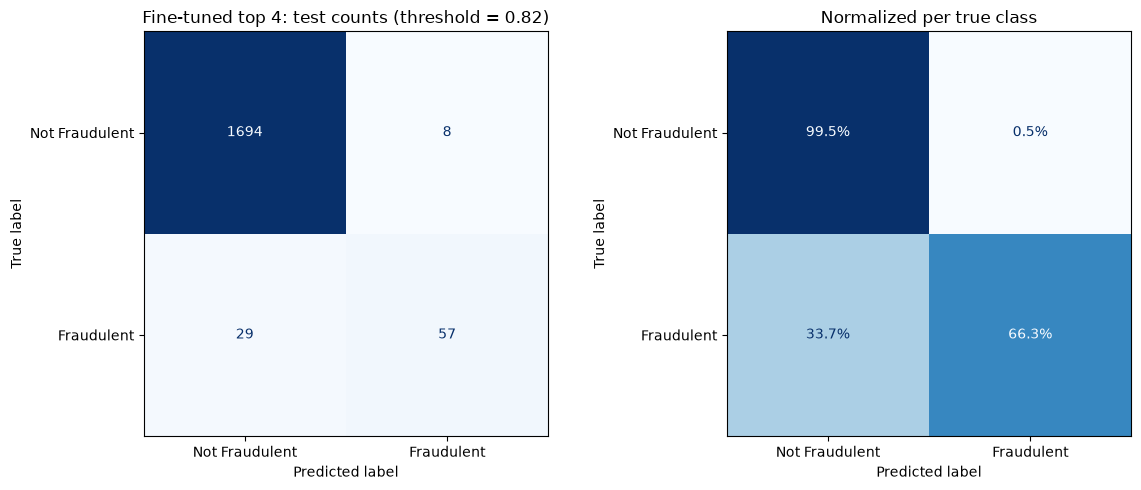

Caught 57 of 86 fraudulent postings, missed 29; 8 real postings flagged as fraud


In [22]:
# load the best weights saved during training
ft_model.load_state_dict(torch.load(save_path))
ft_t, ft_test_probs = evaluate(ft_model, ft_val_loader, ft_test_loader, device, f"Fine-tuned {layers}")

In [ ]:
def classify(text, model=ft_model, threshold=ft_t):
    """Prints the decision for one posting and returns its fraud probability."""
    inputs = tokenizer(text, truncation=True, max_length=512, return_tensors="pt").to(device)
    model.eval()
    with torch.no_grad():
        prob = torch.softmax(model(inputs), dim=-1)[0, 1].item()
    label = "FRAUDULENT" if prob >= threshold else "Real"
    print(f"Fraud probability: {prob:.3f}  (threshold {threshold:.3f})  ->  {label}")
    return prob

# pick a posting from the test set by its position
i = 1400
row = test_df.iloc[i]
print(row[text_ver][:500], "...\n")
print("True label:", "FRAUDULENT" if row["labels"] == 1 else "Real")
classify(row[text_ver])

In [ ]:
fake = {
    "telecommuting": 1, "has_company_logo": 0, "has_questions": 0,
    "title": "Work From Home Data Entry Clerk - Earn $5,000/Week!",
    "location": "US, , ",
    "description": "URGENT HIRING!!! No experience needed! We are a fast-growing international company looking for 10 motivated people to start immediately. Work from the comfort of your home, only 2 hours a day, and earn up to $5,000 per week guaranteed! Your duties are simple: process payments and forward funds to our overseas clients. We will send you a check for the equipment and software you need. Deposit it, keep $500 for yourself, and wire the remaining balance to our supplier. No interview required. No resume needed. Positions are limited and filling fast, so apply today by sending your full name, home address, date of birth, and bank account details to hr.recruitment.global@gmail.com. Start earning TODAY!"
}

real = {
    "telecommuting": 1, "has_company_logo": 0, "has_questions": 0,
    "title": "Software Engineer, Backend (Python)",
    "location": "US, , ",
    "description": "Northwind Logistics is a mid-sized supply chain software company with about 240 employees across offices in Gothenburg and Stockholm. We are looking for a Backend Software Engineer to join our Route Planning team, which builds the services that help carriers plan and track deliveries across the Nordics. In this role you will design, build and maintain Python services and REST APIs, work with PostgreSQL and message queues, and take part in code reviews, on-call rotation (one week in six) and sprint planning. You will work closely with product managers and two frontend engineers in a team of seven."
}

# made-up postings, written with the same builder as the training data
classify(build_text(fake))
classify(build_text(real))

In [ ]:
my_post = {
    "telecommuting": 0, "has_company_logo": 1, "has_questions": 1,
    "title": "Data Entry Clerk - Work From Home",
    "location": "US, , ",
    "description": "Earn $5000 a week from home! No experience needed. Send your bank details to get started today. Not a scam I promise, very legit job on god I need workers",
}
classify(build_text(my_post))